In [113]:
import pandas as pd
import numpy as np
import random
import pyomo.environ as pyo
from pyomo.environ import *
from pyomo.environ import SolverFactory
import yfinance as yf
from pathlib import Path
import os
import matplotlib.pyplot as plt


In [114]:
anos = ['2025-12-31',
 '2024-12-31',
 '2023-12-31',
 '2022-12-31',
 '2021-12-31',
 '2020-12-31',
 '2019-12-31',
 '2018-12-31',
 '2017-12-31',
 '2016-12-31',
 '2015-12-31',
 ]
anos.sort(reverse=False)
anos

['2015-12-31',
 '2016-12-31',
 '2017-12-31',
 '2018-12-31',
 '2019-12-31',
 '2020-12-31',
 '2021-12-31',
 '2022-12-31',
 '2023-12-31',
 '2024-12-31',
 '2025-12-31']

## LER OS RETORNOS, SCORE e SELIC

In [115]:

# Retornos

dfs = {}
for ano in anos:
    ano_usado = ano.split('-')[0]
    nome = f'df_acumulados_ativos_{ano_usado}.csv'
    # caminho = Path('retornos_ativos_otimizacao') / nome
    dfs[ano_usado] = pd.read_csv('../dados_retornos/plotagem/dados/ativo/'+nome)
    dfs[ano_usado]['date'] = pd.to_datetime(dfs[ano_usado]['date'])
    dfs[ano_usado] = dfs[ano_usado].set_index('date')
    dfs[ano_usado] = dfs[ano_usado].drop(columns=dfs[ano_usado].columns[(dfs[ano_usado] == 0).all()])
    print(ano,'-',len(dfs[ano_usado].columns))
    

2015-12-31 - 62
2016-12-31 - 67
2017-12-31 - 70
2018-12-31 - 70
2019-12-31 - 73
2020-12-31 - 73
2021-12-31 - 77
2022-12-31 - 77
2023-12-31 - 78
2024-12-31 - 78
2025-12-31 - 78


In [116]:
dfs['2016']

,ABEV3,ANIM3,AXIA3,AZZA3,B3SA3,BBAS3,BBDC3,BBDC4,BBSE3,BEEF3,...,SLCE3,SMTO3,SUZB3,TAEE11,TOTS3,UGPA3,USIM5,VALE3,VIVT3,WEGE3
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,0.002121,-0.008034,0.034678,-0.023556,0.012355,0.000000,0.021277,0.019584,-0.008755,0.016087,...,0.044302,-0.000413,0.008570,-0.027746,0.014338,-0.004012,-0.011061,0.023766,-0.009787,0.022113
2016-04-04,-0.014843,-0.032433,-0.037885,-0.021932,-0.009619,-0.056652,-0.025493,-0.036662,-0.026152,-0.045739,...,0.016363,-0.085356,0.023534,0.004066,-0.010516,-0.021147,-0.078222,-0.046430,-0.044819,-0.027234
2016-04-05,0.011298,0.058670,0.000000,0.000000,0.012968,-0.016094,0.000330,0.005653,-0.000355,0.000000,...,-0.034584,0.007926,-0.040235,-0.007606,-0.003658,0.015286,-0.030296,0.033810,-0.003331,-0.005017
2016-04-06,-0.011172,-0.030683,-0.066665,-0.017485,-0.042258,-0.009261,-0.028733,-0.030691,-0.016395,-0.007375,...,0.000618,-0.033703,0.010654,-0.003584,0.007716,0.010276,-0.093807,-0.014393,-0.005846,0.010084
2016-04-07,-0.000537,0.051036,0.004865,0.005932,0.012701,0.030814,0.012383,0.008488,0.034051,-0.025065,...,-0.058022,0.017439,-0.004942,0.002569,0.027357,0.010458,0.013808,-0.003975,-0.006165,-0.006418
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-03-27,0.009078,-0.015574,-0.054153,-0.012862,-0.001615,0.003312,0.007840,0.008513,-0.022061,0.060539,...,-0.023253,0.016000,-0.026231,0.004096,-0.015037,0.010913,0.086432,0.013444,-0.011202,0.010426
2017-03-28,0.008428,-0.003772,-0.036127,0.026059,-0.000517,-0.006303,0.011519,0.005620,0.009866,0.014762,...,0.013941,0.009564,0.020673,0.017231,-0.001454,0.002104,-0.013651,0.014297,-0.013163,0.014733
2017-03-29,0.013377,0.003024,-0.010955,-0.004764,0.036413,0.036249,0.003389,0.020826,0.025832,-0.020359,...,0.004569,-0.025072,-0.015191,0.014266,-0.025494,0.014268,0.023036,0.010058,0.012812,0.013352


In [117]:
# df_portfolios = pd.read_csv('../carteiras/minima_variancia/carteiras_minvar.csv').drop(columns='Unnamed: 0')
# df_portfolios
df_portfolios = pd.read_csv('../carteiras/goal_programming/carteiras_goal_programming.csv').drop(columns='Unnamed: 0')
df_portfolios

,ano,ativo,peso
0,2016,ABEV3,0.02
1,2016,COGN3,0.02
2,2016,FLRY3,0.20
3,2016,ISAE4,0.02
4,2016,LREN3,0.20
...,...,...,...
104,2026,JHSF3,0.20
105,2026,LREN3,0.20
106,2026,PETR3,0.02
107,2026,PETR4,0.02


In [118]:
anos.append('2026-12-30')

In [213]:
nomes_carteiras = list(os.listdir('../carteiras/'))

In [215]:
os.listdir('../carteiras/'+nomes_carteiras[0])

['carteiras_goal_programming.csv']

      ano  ativo  peso
0    2016  ABEV3  0.02
1    2016  COGN3  0.02
2    2016  FLRY3  0.20
3    2016  ISAE4  0.02
4    2016  LREN3  0.20
..    ...    ...   ...
104  2026  JHSF3  0.20
105  2026  LREN3  0.20
106  2026  PETR3  0.02
107  2026  PETR4  0.02
108  2026  TEND3  0.02

[109 rows x 3 columns]
      ano   ativo    peso
0    2016   BRKM5  0.0528
1    2016   EMBJ3  0.0685
2    2016  ENGI11  0.1592
3    2016   HYPE3  0.2000
4    2016   JHSF3  0.0468
..    ...     ...     ...
105  2026   POMO4  0.0657
106  2026   PRIO3  0.1186
107  2026   PSSA3  0.0776
108  2026   SUZB3  0.2000
109  2026   TOTS3  0.0594

[110 rows x 3 columns]
      ano  ativo    peso
0    2016  CSAN3  0.1430
1    2016  DIRR3  0.0868
2    2016  FLRY3  0.1218
3    2016  HYPE3  0.2000
4    2016  MGLU3  0.0614
..    ...    ...     ...
103  2026  PRIO3  0.1686
104  2026  SLCE3  0.0337
105  2026  USIM5  0.0455
106  2026  VALE3  0.0947
107  2026  WEGE3  0.0924

[108 rows x 3 columns]
      ano  ativo    peso
0    2016  CSAN

In [248]:


retorno_ibov = []
acumulado_ibov = 1.0
ll=[]
for an in anos:
            
    ano = an.split('-')[0]
    if ano == '2015' or ano=='2026':
        continue
    # ---------- IBOV

    df_ibov = pd.read_csv(f'../dados_retornos/plotagem/dados/ibov/df_ibov_{ano}.csv', index_col='Date', parse_dates=True)
    df_ibov = df_ibov['IBOV']
    ibov_acumulado = (df_ibov+1).cumprod()
    ibov_acumulado = ibov_acumulado*acumulado_ibov
    acumulado_ibov = ibov_acumulado.iloc[-1]
    
    retorno_ibov.append(ibov_acumulado)


for nc in nomes_carteiras:
    retorno_series = []
    acumulado = 1.0
    for n in os.listdir('../carteiras/'+nc):
        df_portfolios = pd.read_csv(f'../carteiras/{nc}/{n}').drop(columns='Unnamed: 0')
        for an in anos:
            
            ano = an.split('-')[0]
            if ano == '2015' or ano=='2026':
                continue
            carteira = df_portfolios[df_portfolios['ano']==int(ano)]
            ativos = carteira['ativo'].tolist()
            pesos = carteira['peso'].tolist()
            #calculo do turnover, uma lista com peso de tudo, os que não estao na carteira vira zero, 
            #pegar info ano anterior
            carteira_t_1 = df_portfolios[df_portfolios['ano']==int(ano)-1]
            ativos_t_1 = carteira_t_1['ativo'].tolist()
            pesos_t_1 = carteira_t_1['peso'].tolist()
            pesos_t   = carteira.set_index('ativo')['peso']
            pesos_t_1 = carteira_t_1.set_index('ativo')['peso']
            turnover  = pesos_t.subtract(pesos_t_1, fill_value=0).abs().sum() / 2
            df = dfs[ano].copy()
            df = df[ativos]
            retorno_df = ((df*pesos).sum(axis=1)+1).cumprod()
            retorno_df = retorno_df*acumulado*(1-0.0003*turnover)
            acumulado = retorno_df.iloc[-1]
            retorno_series.append(retorno_df)
            

    ll.append(retorno_series)

    



In [249]:
print(nomes_carteiras)
ll[2]

['goal_programming', 'minima_variancia', 'retorno_magic_formula_sharpe_bissecao', 'retorno_piotroski_sharpe_bissecao', 'sharpe_linear_magic_formula', 'sharpe_linear_piotroski']


[date
 2016-04-01    1.007493
 2016-04-04    0.981465
 2016-04-05    0.981417
 2016-04-06    0.970431
 2016-04-07    0.974050
                 ...   
 2017-03-27    1.455501
 2017-03-28    1.454678
 2017-03-29    1.469214
 2017-03-30    1.464975
 2017-03-31    1.456180
 Length: 251, dtype: float64,
 date
 2017-04-03    1.463459
 2017-04-04    1.479101
 2017-04-05    1.466058
 2017-04-06    1.434321
 2017-04-07    1.429024
                 ...   
 2018-03-23    2.225320
 2018-03-26    2.244889
 2018-03-27    2.231389
 2018-03-28    2.215214
 2018-03-29    2.227024
 Length: 244, dtype: float64,
 date
 2018-04-02    2.210596
 2018-04-03    2.212408
 2018-04-04    2.219919
 2018-04-05    2.258322
 2018-04-06    2.273205
                 ...   
 2019-03-25    3.319661
 2019-03-26    3.361931
 2019-03-27    3.278622
 2019-03-28    3.308456
 2019-03-29    3.342935
 Length: 245, dtype: float64,
 date
 2019-04-01    3.347767
 2019-04-02    3.331115
 2019-04-03    3.372904
 2019-04-04    3.41486

In [250]:
retorno_ibov

[Date
 2016-04-01    1.010129
 2016-04-04    0.974528
 2016-04-05    0.980002
 2016-04-06    0.960863
 2016-04-07    0.969194
                 ...   
 2017-03-27    1.284747
 2017-03-28    1.291379
 2017-03-29    1.309120
 2017-03-30    1.303886
 2017-03-31    1.298252
 Name: IBOV, Length: 251, dtype: float64,
 Date
 2017-04-03    1.302787
 2017-04-04    1.313935
 2017-04-05    1.294077
 2017-04-06    1.283049
 2017-04-07    1.290441
                 ...   
 2018-03-23    1.685686
 2018-03-26    1.699890
 2018-03-27    1.674318
 2018-03-28    1.675637
 2018-03-29    1.705444
 Name: IBOV, Length: 244, dtype: float64,
 Date
 2018-04-02    1.691459
 2018-04-03    1.690600
 2018-04-04    1.685346
 2018-04-05    1.702327
 2018-04-06    1.694536
                 ...   
 2019-03-25    1.871182
 2019-03-26    1.904046
 2019-03-27    1.836040
 2019-03-28    1.885706
 2019-03-29    1.906203
 Name: IBOV, Length: 245, dtype: float64,
 Date
 2019-04-01    1.918969
 2019-04-02    1.905644
 2019-04-0

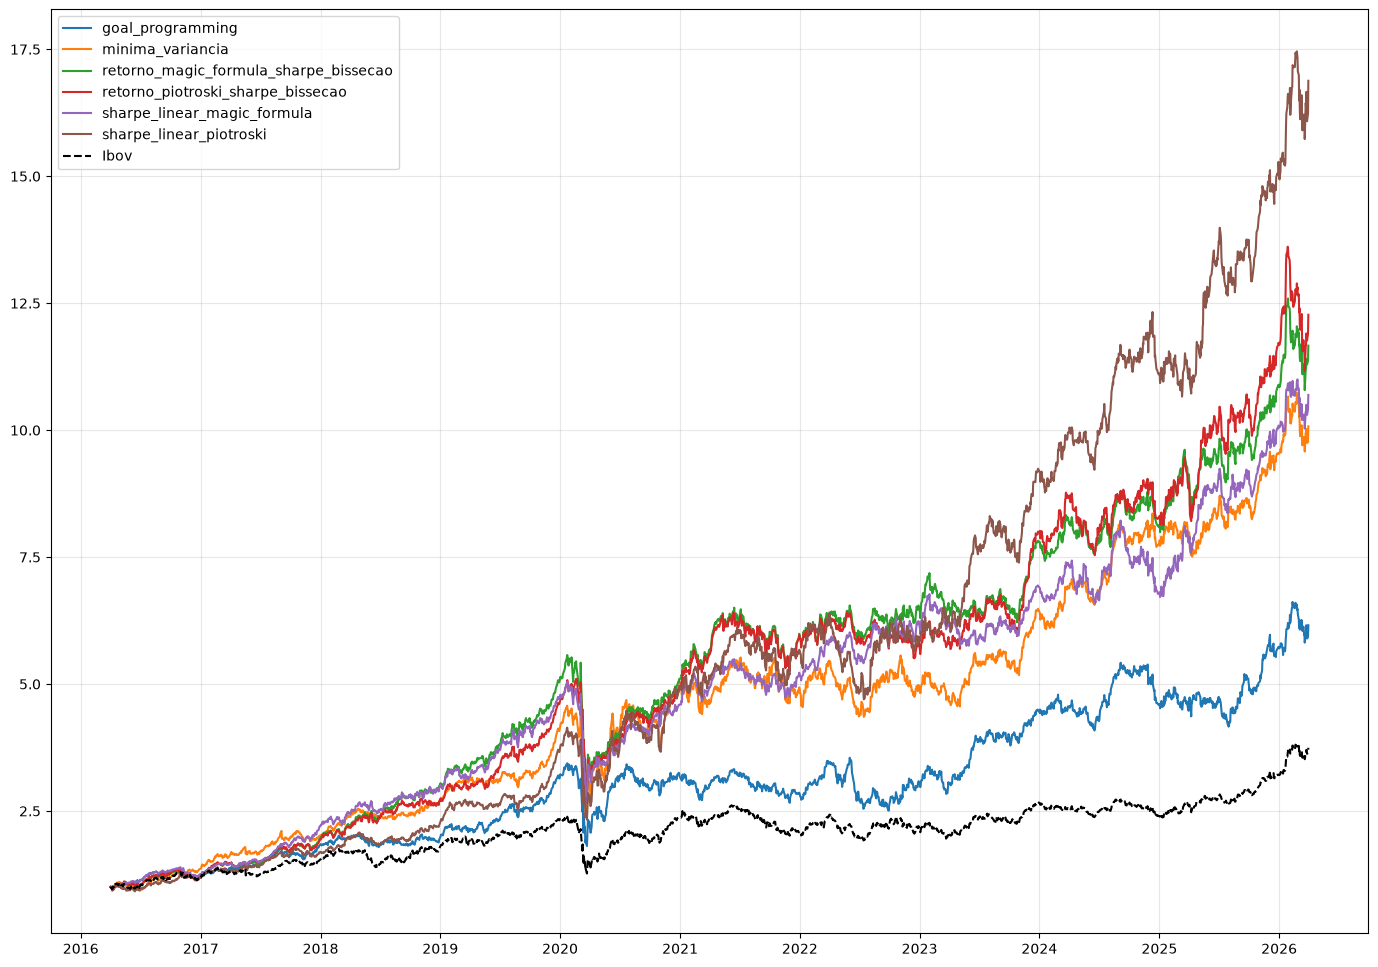

In [262]:
plt.figure(figsize=(17,12))
for v in range(len(ll)):    
    retorno_final = pd.concat(ll[v])
    retorno_ibov_final = pd.concat(retorno_ibov)

    plt.plot(retorno_final.index, retorno_final, label=nomes_carteiras[v])
    


    # plt.axhline(11, color='gray', linewidth=0.8)
    
plt.plot(retorno_ibov_final.index, retorno_ibov_final, label="Ibov",color='black', linestyle='--')
plt.legend()
plt.grid(alpha=0.3)
# plt.yscale('log')
plt.show()


